# ETL Project — Traffic Collisions Analysis

# Objective

In this case study, you will be working on California Traffic Collision Data Analysis using Apache Spark, a powerful distributed computing framework designed for big data processing. This assignment aims to provide hands-on experience in analyzing large-scale traffic collision datasets using PySpark and AWS services. You will apply data analytics techniques to clean, transform, and explore crash data, drawing meaningful insights to support traffic safety and urban planning. Beyond understanding how big data tools optimize performance on a single machine and across clusters, you will develop a structured approach to analyzing crash trends, identifying high-risk locations, and evaluating contributing factors to traffic incidents. Additionally, you will utilize AWS S3 to store the processed data efficiently after the ETL process, enabling scalable storage and easy retrieval for further analysis.


# Business Value:

Traffic collisions pose significant risks to public safety, requiring continuous monitoring and analysis to enhance road safety measures. Government agencies, city planners, and policymakers must leverage data-driven insights to improve infrastructure, optimize traffic management, and implement preventive measures.

In this assignment, you will analyze California traffic collision data to uncover patterns related to accident severity, location-based risks, and key contributing factors. With Apache Spark's ability to handle large datasets efficiently and AWS S3's scalable storage, transportation authorities can process vast amounts of crash data in real time, enabling faster and more informed decision-making.

As an analyst examining traffic safety trends, your task is to analyze historical crash data to derive actionable insights that can drive policy improvements and safety interventions. Your analysis will help identify high-risk areas, categorize accidents by severity and contributing factors, and store the processed data in an AWS S3 bucket for scalable and long-term storage.

By leveraging big data analytics and cloud-based storage, urban planners and traffic authorities can enhance road safety strategies, reduce accident rates, and improve public transportation planning.


# Dataset Overview

The dataset used in this analysis consists of California traffic collision data obtained from the Statewide Integrated Traffic Records System (SWITRS). It includes detailed records of traffic incidents across California, covering various attributes such as location, severity, involved parties, and contributing factors. The dataset has been preprocessed and transformed using PySpark to facilitate large-scale analysis. By leveraging Apache Spark, we ensure efficient data handling, enabling deeper insights into traffic patterns, accident trends, and potential safety improvements.

The dataset is a .sqlite file contains detailed information about traffic collisions across California and is structured into four primary tables:
- `collisions` table contains information about the collision, where it happened, what vehicles were involved.

- `parties` table contains information about the groups people involved in the collision including age, sex, and sobriety.

- `victims` table contains information about the injuries of specific people involved in the collision.

- `locations` table contains information about the geographical location and details of road intersections.

## Data Integrity and Execution Notes
- The supplied archive contains four CSV files: `sample_collisions.csv`, `sample_parties.csv`, `sample_victims.csv`, and `sample_case_ids.csv`.
- Keep the four files in `/content/drive/MyDrive/Project/Crash_Data` after extracting the archive.
- Collision-level counts are computed from the collision table. Party- and victim-level records must not be treated as collision counts.
- The supplied extract has substantial missingness in some location-related fields and the collision-level `killed_victims` field must be validated before using it for a fatality percentage.
- The notebook is designed for Google Colab and includes Drive mounting. This environment cannot authenticate to the user's Google Drive; run it in Colab to generate live notebook outputs.


# Assignment Tasks

<ol>
    <li>
        <strong>Data Preparation</strong></br>
        The dataset consists of structured tables containing traffic collision data. Before conducting any analysis, it is essential to ensure that the data is properly formatted and structured for efficient processing.</br>
        Check for data consistency and ensure all columns are correctly formatted.</br>
        Apply sampling techniques if needed to extract a representative subset for analysis.</br>
        Structure and prepare the data for further processing and analysis.</br>
    </br>
    <li>
        <strong>Data Cleaning</strong></br>
            2.1 <strong>Fixing Columns:</strong> Ensure all columns are properly named and formatted.</br>
            2.2 <strong>Handling Missing Values:</strong> Decide on an approach to handle missing data (e.g., imputation or removal). Mention the approach in your report.</br>
            2.3 <strong>Handling Outliers:</strong> Identify outliers in the dataset and explain why they are considered outliers. It is not necessary to remove them for this task, but mention your approach for handling them.</br>
    </br>
    <li>
        <strong>Exploratory Data Analysis</strong></br>
        Finding Patterns and analyze the dataset and find patterns based on the following points:
                <ul>
                3.1 Classify variables into categorical and numerical types.</br>
                3.2 Analyze the distribution of collision severity.</br>
                3.3 Examine weather conditions during collisions.</br>
                3.4 Analyze the distribution of victim ages.</br>
                3.5 Study the relationship between collision severity and the number of victims.</br>
                3.6 Analyze the correlation between weather conditions and collision severity.</br>
                3.7 Visualize the impact of lighting conditions on collision severity.</br>
                3.8 Extract and analyze weekday-wise collision trends.</br>
                3.9 Assess the number of collisions occurring on different days of the week.</br>
                3.10 Study spatial distribution of collisions by county.</br>
                3.11 Generate a scatter plot to analyze collision locations geographically.</br>
                3.12 Extract and analyze collision trends over time, including yearly, monthly, and hourly trends.</br>
</ul>
</br>
<li>
<strong>ETL Querying</strong><br>
Write PySpark SQL queries for the following:</br>
<ol>
    4.1. Identify the top 5 counties with the highest number of collisions.</br>
    4.2. Identify the month with the highest number of collisions.</br>
    4.3. Determine the most common weather condition during collisions.</br>
    4.4. Calculate the percentage of collisions that resulted in fatalities.</br>
    4.5. Find the most dangerous time of day for collisions.</br>
    4.6. Identify the top 5 road surface conditions with the highest collision frequency.</br>
    4.7. Analyze lighting conditions that contribute to the highest number of collisions.</br>
</ol>
</br>
<li>
<strong>Conclusion</strong></br>
Provide final insights and recommendations based on the analysis:
    <ul>
        5.1 Recommendations to improve road safety by identifying high-risk locations and peak accident times for infrastructure improvements.</br>
        5.2 Suggestions to optimize traffic management by analyzing trends in collision severity, weather conditions, and lighting to improve road design and traffic signal timing.</br>
        5.3 Propose data-driven policy changes to enhance pedestrian and cyclist safety based on collision trends involving vulnerable road users.</br>
        5.4 Identify potential high-risk zones for proactive intervention by examining geographic collision density and historical accident data.</br>
        5.5 Assess the impact of environmental factors such as weather, road surface conditions, and lighting on accident frequency and severity.</br>
        5.6 Develop predictive models to anticipate collision hotspots and support proactive safety measures.</br>
        </ul>
        Conclude the analysis by summarizing key findings and business implications.</br>
        Explain the results of univariate, segmented univariate, and bivariate analyses in real-world traffic safety and policy terms.</br>
        Include visualizations and summarize the most important results in the report. Insights should explain why each variable is important and how they can influence traffic safety policies and urban planning.</br>
        </ul>
        </br>
    <li>
    <strong>Visualization Integration [Optional]</strong>
    <p>Enhance the project by incorporating a visualization component that connects the processed data stored in an S3 bucket to a business intelligence tool such as Tableau or Power BI. This involves setting up the connection between the S3 bucket and the chosen visualization tool, importing the processed dataset for analysis and visualization, creating interactive dashboards to explore key trends and insights and ensuring data updates are reflected dynamically in the visualization tool.<br>
</br>
</ol>

Install Required Libraries

In [1]:
# Google Colab / Google Drive setup (required)
from google.colab import drive
drive.mount('/content/drive')
import os
DATA_DIR = '/content/drive/MyDrive/Project/Crash_Data'
OUTPUT_DIR = os.path.join(DATA_DIR, 'outputs')
os.makedirs(OUTPUT_DIR, exist_ok=True)
print('Dataset directory:', DATA_DIR)
print('Files:', os.listdir(DATA_DIR))

Mounted at /content/drive
Dataset directory: /content/drive/MyDrive/Project/Crash_Data
Files: ['sample_case_ids.csv', 'sample_victims.csv', 'sample_parties.csv', 'sample_collisions.csv', 'outputs']


In [2]:
%pip install pyspark==4.0.1

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 434.2/434.2 MB 4.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pyspark: filename=pyspark-4.0.1-py2.py3-none-any.whl size=434813860 sha256=03c9dfa8e06914d3fe0cd7e2c3e76aa411cab32dd0ffac3ae669621819f31fdf
  Stored in directory: /root/.cache/pip/wheels/00/e3/92/8594f4cee2c9fd4ad82fe85e4bf2559ab8ea84ef19b1dd3d15
Successfully built pyspark
  Attempting uninstall: pyspark
    Found existing installation: pyspark 4.0.4
    Uninstalling pyspark-4.0.4:
      Successfully uninstalled pyspark-4.0.4


In [3]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("TrafficCollisionsETL")
    .getOrCreate()
)

print("Spark version:", spark.version)
print("Spark started successfully!")

Spark version: 4.0.1
Spark started successfully!


In [4]:
spark = (SparkSession.builder.appName('TrafficCollisionsETL').getOrCreate())

In [5]:
from pyspark.sql import SparkSession, functions as F

In [6]:
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import *
warnings.filterwarnings('ignore')
spark = (SparkSession.builder.appName('TrafficCollisionsETL').getOrCreate())
spark.conf.set('spark.sql.shuffle.partitions', '8')
print('Spark version:', spark.version)

Spark version: 4.0.1


#**1. Data Preparation** <font color = red>[5 marks]</font> <br>

The dataset consists of structured tables containing traffic collision data.

Before conducting any analysis, it is essential to ensure that the data is properly formatted and structured for efficient processing.

Check for data consistency and ensure all columns are correctly formatted.

In [7]:
# Load the supplied CSV tables from Google Drive. Keep IDs as strings to avoid precision loss.
required_files = {
    'collisions': 'sample_collisions.csv',
    'parties': 'sample_parties.csv',
    'victims': 'sample_victims.csv',
    'case_ids': 'sample_case_ids.csv'
}
missing_files = [f for f in required_files.values() if not os.path.isfile(os.path.join(DATA_DIR, f))]
if missing_files:
    raise FileNotFoundError(f'Missing required file(s) in {DATA_DIR}: {missing_files}. Extract Crash_Data_Analysis_Dataset.zip into this folder.')
def read_csv_safely(filename):
    path = os.path.join(DATA_DIR, filename)
    return (spark.read.option('header', True).option('inferSchema', True)
            .option('mode', 'PERMISSIVE').option('multiLine', False).csv(path))
collisions_raw = spark.read.option('header', True).option('inferSchema', False).csv(os.path.join(DATA_DIR, required_files['collisions']))
parties_raw = spark.read.option('header', True).option('inferSchema', False).csv(os.path.join(DATA_DIR, required_files['parties']))
victims_raw = spark.read.option('header', True).option('inferSchema', False).csv(os.path.join(DATA_DIR, required_files['victims']))
case_ids_raw = spark.read.option('header', True).option('inferSchema', False).csv(os.path.join(DATA_DIR, required_files['case_ids']))
print('Collision rows:', collisions_raw.count(), 'columns:', len(collisions_raw.columns))
print('Party rows:', parties_raw.count(), 'columns:', len(parties_raw.columns))
print('Victim rows:', victims_raw.count(), 'columns:', len(victims_raw.columns))
collisions_raw.printSchema()
collisions_raw.show(5, truncate=False)

Collision rows: 935791 columns: 65
Party rows: 1866917 columns: 24
Victim rows: 963933 columns: 11
root
 |-- case_id: string (nullable = true)
 |-- jurisdiction: string (nullable = true)
 |-- officer_id: string (nullable = true)
 |-- reporting_district: string (nullable = true)
 |-- chp_shift: string (nullable = true)
 |-- population: string (nullable = true)
 |-- county_city_location: string (nullable = true)
 |-- county_location: string (nullable = true)
 |-- special_condition: string (nullable = true)
 |-- beat_type: string (nullable = true)
 |-- chp_beat_type: string (nullable = true)
 |-- chp_beat_class: string (nullable = true)
 |-- beat_number: string (nullable = true)
 |-- primary_road: string (nullable = true)
 |-- secondary_road: string (nullable = true)
 |-- distance: string (nullable = true)
 |-- direction: string (nullable = true)
 |-- intersection: string (nullable = true)
 |-- weather_1: string (nullable = true)
 |-- state_highway_indicator: string (nullable = true)
 |--

#**2. Data Cleaning** <font color = red>[20 marks]</font> <br>


In [8]:
# Display schemas and samples for all supplied tables.
for name, frame in [('collisions', collisions_raw), ('parties', parties_raw), ('victims', victims_raw), ('case_ids', case_ids_raw)]:
    print(f'--- {name}: {frame.count():,} rows, {len(frame.columns)} columns ---')
    frame.printSchema()
    frame.show(3, truncate=50)

--- collisions: 935,791 rows, 65 columns ---
root
 |-- case_id: string (nullable = true)
 |-- jurisdiction: string (nullable = true)
 |-- officer_id: string (nullable = true)
 |-- reporting_district: string (nullable = true)
 |-- chp_shift: string (nullable = true)
 |-- population: string (nullable = true)
 |-- county_city_location: string (nullable = true)
 |-- county_location: string (nullable = true)
 |-- special_condition: string (nullable = true)
 |-- beat_type: string (nullable = true)
 |-- chp_beat_type: string (nullable = true)
 |-- chp_beat_class: string (nullable = true)
 |-- beat_number: string (nullable = true)
 |-- primary_road: string (nullable = true)
 |-- secondary_road: string (nullable = true)
 |-- distance: string (nullable = true)
 |-- direction: string (nullable = true)
 |-- intersection: string (nullable = true)
 |-- weather_1: string (nullable = true)
 |-- state_highway_indicator: string (nullable = true)
 |-- caltrans_county: string (nullable = true)
 |-- caltra

##**2.1 Missing Values** <font color = red>[10 marks]</font> <br>


In [9]:
# Missing-value proportions (empty strings are treated as missing).
def missing_profile(df):
    exprs = [F.round(F.sum(F.when(F.col(c).isNull() | (F.trim(F.col(c)) == ''), 1).otherwise(0))/F.count('*')*100, 2).alias(c) for c in df.columns]
    return df.agg(*exprs).toPandas().T.rename(columns={0:'missing_pct'}).sort_values('missing_pct', ascending=False)
missing_profile(collisions_raw).head(20)

,missing_pct
location_type,72.89
caltrans_county,72.89
side_of_highway,72.89
longitude,71.50
latitude,71.50
state_route,69.32
postmile,69.32
caltrans_district,69.32
pcf_violation_subsection,64.27
reporting_district,59.06


In [10]:
# Avoid dropping sparse columns automatically: several location fields are legitimately not applicable to many records.
missing_profile(collisions_raw).query('missing_pct >= 60')

,missing_pct
location_type,72.89
caltrans_county,72.89
side_of_highway,72.89
longitude,71.50
latitude,71.50
state_route,69.32
postmile,69.32
caltrans_district,69.32
pcf_violation_subsection,64.27


In [11]:
# Convert known numeric/date/time columns carefully; invalid values become null rather than crashing the pipeline.
numeric_cols = ['killed_victims','injured_victims','party_count','latitude','longitude','distance','postmile',
                'severe_injury_count','other_visible_injury_count','complaint_of_pain_injury_count',
                'pedestrian_killed_count','pedestrian_injured_count','bicyclist_killed_count','bicyclist_injured_count',
                'motorcyclist_killed_count','motorcyclist_injured_count']
collisions = collisions_raw
for c in numeric_cols:
    if c in collisions.columns:
        collisions = collisions.withColumn(c, F.when(F.trim(F.col(c)) == '', None).otherwise(F.col(c).cast('double')))
collisions = (collisions
    .withColumn('collision_date_parsed', F.to_date('collision_date', 'yyyy-MM-dd'))
    .withColumn('collision_time_parsed', F.to_timestamp('collision_time', 'HH:mm:ss'))
    .withColumn('collision_year', F.year('collision_date_parsed'))
    .withColumn('collision_month', F.month('collision_date_parsed'))
    .withColumn('collision_hour', F.hour('collision_time_parsed'))
    .withColumn('weekday', F.date_format('collision_date_parsed', 'EEEE')))
print('Rows after type conversion:', collisions.count())
collisions.select('collision_date','collision_date_parsed','collision_time','collision_hour').show(5, truncate=False)

Rows after type conversion: 935791
+--------------+---------------------+--------------+--------------+
|collision_date|collision_date_parsed|collision_time|collision_hour|
+--------------+---------------------+--------------+--------------+
|2016-03-20    |2016-03-20           |16:30:00      |16            |
|2009-04-13    |2009-04-13           |18:24:00      |18            |
|2021-01-09    |2021-01-09           |18:15:00      |18            |
|2007-06-16    |2007-06-16           |21:50:00      |21            |
|2020-04-14    |2020-04-14           |17:56:00      |17            |
+--------------+---------------------+--------------+--------------+
only showing top 5 rows


In [12]:
# Handle missing categorical values transparently with an explicit label only in analysis outputs.
# Preserve the raw nulls in the cleaned base; do not impute unknown weather/lighting/road data.
clean_collisions = collisions.dropDuplicates(['case_id'])
print('Rows before duplicate-key handling:', collisions.count())
print('Unique case IDs:', clean_collisions.count())
print('Missing values remain documented in the profile; analysis uses non-null values per question.')

Rows before duplicate-key handling: 935791
Unique case IDs: 935764
Missing values remain documented in the profile; analysis uses non-null values per question.


##**2.2 Fixing Columns** <font color = red>[5 marks]</font> <br>


In [13]:
# Duplicate diagnostics: distinguish exact duplicate rows from repeated collision keys.
exact_dupes = collisions_raw.count() - collisions_raw.dropDuplicates().count()
duplicate_keys = collisions_raw.count() - collisions_raw.dropDuplicates(['case_id']).count()
print(f'Exact duplicate rows: {exact_dupes:,}')
print(f'Rows beyond first occurrence of case_id: {duplicate_keys:,}')
# Use one row per case_id for collision-level analyses to avoid duplicate collision counting.
clean_collisions = collisions.dropDuplicates(['case_id'])

Exact duplicate rows: 0
Rows beyond first occurrence of case_id: 27


In [14]:
# IQR screening on numeric fields. Flag outliers for review; do not remove plausible extreme values automatically.
iqr_cols = [c for c in ['distance','latitude','longitude','killed_victims','injured_victims','party_count'] if c in clean_collisions.columns]
for c in iqr_cols:
    q = clean_collisions.approxQuantile(c, [0.25, 0.75], 0.01)
    if len(q) == 2:
        iqr = q[1] - q[0]; low = q[0] - 1.5*iqr; high = q[1] + 1.5*iqr
        count = clean_collisions.filter((F.col(c) < low) | (F.col(c) > high)).count()
        print(f'{c}: Q1={q[0]:.3f}, Q3={q[1]:.3f}, IQR bounds=({low:.3f}, {high:.3f}), flagged={count:,}')

distance: Q1=1.000, Q3=500.000, IQR bounds=(-747.500, 1248.500), flagged=104,630
latitude: Q1=33.951, Q3=37.578, IQR bounds=(28.510, 43.019), flagged=0
longitude: Q1=-121.379, Q3=-117.917, IQR bounds=(-126.572, -112.723), flagged=0
killed_victims: Q1=0.000, Q3=0.000, IQR bounds=(0.000, 0.000), flagged=0
injured_victims: Q1=0.000, Q3=1.000, IQR bounds=(-1.500, 2.500), flagged=33,313
party_count: Q1=2.000, Q3=2.000, IQR bounds=(2.000, 2.000), flagged=298,305


##**2.3 Outlier Analysis** <font color = red>[5 marks]</font> <br>


In [15]:
# No blanket outlier removal: keep source values unless a verified data error is identified.
# Invalid coordinates are excluded only from geographic plots, not from collision totals.
clean_collisions = clean_collisions.withColumn(
    'coordinate_valid',
    F.col('latitude').between(-90,90) & F.col('longitude').between(-180,180)
)
print('Analysis base rows:', clean_collisions.count())
print('Valid coordinate rows:', clean_collisions.filter('coordinate_valid').count())

Analysis base rows: 935764
Valid coordinate rows: 266742


#**3. Exploratory Data Analysis** <font color = red>[65 marks]</font> <br>


##**3.1.1. Data Preparation** <font color = red>[5 marks]</font> <br>

Q: Classify variables into categorical and numerical.

In [16]:
# Classify columns using Spark schema; this is a descriptive type classification, not model encoding.
numeric_types = ('int','bigint','double','float','decimal','long','short')
schema_rows = [(f.name, f.dataType.simpleString(), 'numerical' if any(t in f.dataType.simpleString().lower() for t in numeric_types) else 'categorical/text') for f in clean_collisions.schema.fields]
variable_classification = pd.DataFrame(schema_rows, columns=['column','spark_type','classification'])
display(variable_classification)
# Keep original category labels for interpretable descriptive analysis; encoding is not required for these plots.

,column,spark_type,classification
0,case_id,string,categorical/text
1,jurisdiction,string,categorical/text
2,officer_id,string,categorical/text
3,reporting_district,string,categorical/text
4,chp_shift,string,categorical/text
...,...,...,...
67,collision_year,int,numerical
68,collision_month,int,numerical
69,collision_hour,int,numerical
70,weekday,string,categorical/text


In [17]:
# Standardized analytical frame with consistent parsed date fields and a collision-level key.
analysis_collisions = clean_collisions
analysis_collisions = analysis_collisions.withColumn('county_location_clean', F.lower(F.trim(F.col('county_location'))))
analysis_collisions = analysis_collisions.withColumn('weather_clean', F.lower(F.trim(F.col('weather_1'))))
analysis_collisions = analysis_collisions.withColumn('lighting_clean', F.lower(F.trim(F.col('lighting'))))
analysis_collisions = analysis_collisions.withColumn('road_surface_clean', F.lower(F.trim(F.col('road_surface'))))

In [18]:
# Final cleaned dataset summary. Save to Drive in Parquet for optional reuse; source files remain unchanged.
analysis_collisions.select('case_id','county_location','collision_severity','weather_1','road_surface','lighting',
                           'collision_date_parsed','collision_time_parsed','latitude','longitude').show(10, truncate=False)
print('Collision-level records:', analysis_collisions.count())
print('Columns:', len(analysis_collisions.columns))

+----------------------+---------------+--------------------+---------+------------+-----------------------+---------------------+---------------------+--------+---------+
|case_id               |county_location|collision_severity  |weather_1|road_surface|lighting               |collision_date_parsed|collision_time_parsed|latitude|longitude|
+----------------------+---------------+--------------------+---------+------------+-----------------------+---------------------+---------------------+--------+---------+
|1.0000108292315094e+18|fresno         |property damage only|clear    |dry         |dark with street lights|2001-08-29           |1970-01-01 23:15:00  |NULL    |NULL     |
|1.0000111230859023e+18|fresno         |property damage only|clear    |dry         |daylight               |2001-11-23           |1970-01-01 08:59:00  |NULL    |NULL     |
|1.0001010317450314e+17|alameda        |pain                |clear    |dry         |dark with street lights|2001-01-03           |1970-01-01

Loading the Final Cleaned Dataset into S3 Bucket

##**3.1.2. Analyze the distribution of collision severity.** <font color = red>[5 marks]</font> <br>

Q: Analyze the distribution of collision severity.

,collision_severity,count
0,property damage only,570460
1,pain,226486
2,other injury,116680
3,severe injury,22138


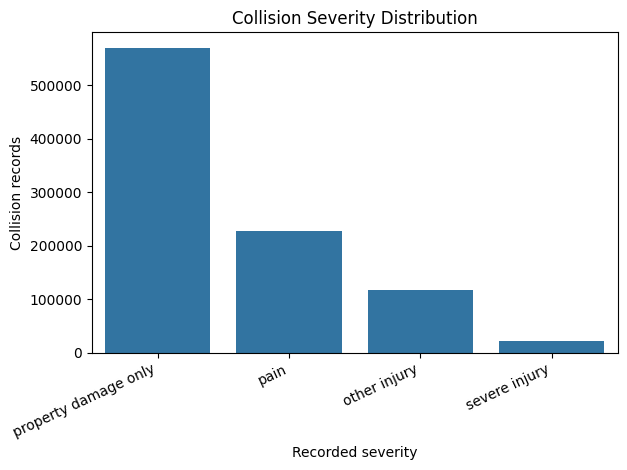

In [19]:
# Collision severity distribution (full collision-level dataset)
pdf = analysis_collisions.groupBy('collision_severity').count().orderBy(F.desc('count')).toPandas()
display(pdf)
sns.barplot(data=pdf, x='collision_severity', y='count')
plt.title('Collision Severity Distribution'); plt.xlabel('Recorded severity'); plt.ylabel('Collision records'); plt.xticks(rotation=25, ha='right'); plt.tight_layout(); plt.show()

##**3.1.3. Weather conditions during collisions.** <font color = red>[5 marks]</font> <br>

Q: Examine weather conditions during collisions.

,weather_clean,count
0,clear,769905
1,cloudy,122150
2,raining,32341
3,None,4626
4,fog,3901
5,snowing,1370
6,other,1081
7,wind,390


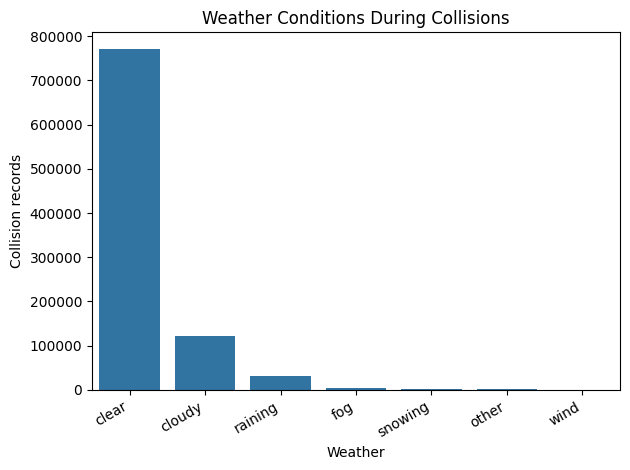

In [20]:
pdf = analysis_collisions.groupBy('weather_clean').count().orderBy(F.desc('count')).limit(12).toPandas()
display(pdf)
sns.barplot(data=pdf, x='weather_clean', y='count'); plt.title('Weather Conditions During Collisions'); plt.xlabel('Weather'); plt.ylabel('Collision records'); plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

##**3.1.4. Victime Age Distribution.** <font color = red>[5 marks]</font> <br>

Q: Analyze the distribution of victim ages.

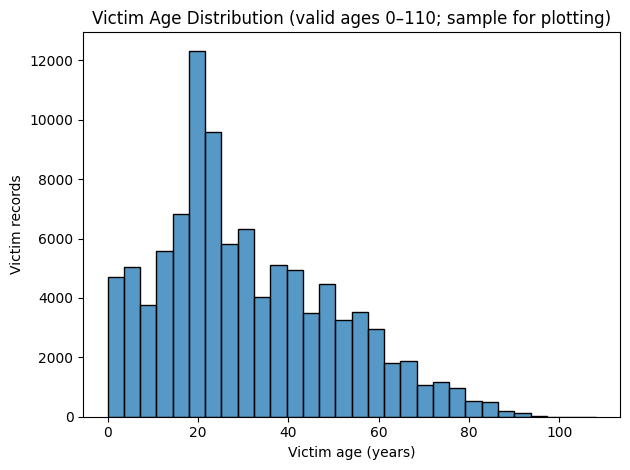

Victim age values outside 0–110 are excluded from this visualization only; source records are retained.


In [21]:
victim_age = victims_raw.withColumn('victim_age_num', F.col('victim_age').cast('double'))
age_pdf = victim_age.filter(F.col('victim_age_num').between(0,110)).select('victim_age_num').sample(False, 0.2, seed=42).limit(100000).toPandas()
sns.histplot(data=age_pdf, x='victim_age_num', bins=30); plt.title('Victim Age Distribution (valid ages 0–110; sample for plotting)'); plt.xlabel('Victim age (years)'); plt.ylabel('Victim records'); plt.tight_layout(); plt.show()
print('Victim age values outside 0–110 are excluded from this visualization only; source records are retained.')

##**3.1.5. Collision Severity vs Number of Victims.** <font color = red>[5 marks]</font> <br>

Q: Study the relationship between collision severity and the number of victims.

,collision_severity,mean_recorded_victims,median_recorded_victims,collisions
0,pain,1.369104,1.0,226486
1,property damage only,0.000000,0.0,570460
2,other injury,1.513241,1.0,116680
3,severe injury,1.620652,1.0,22138


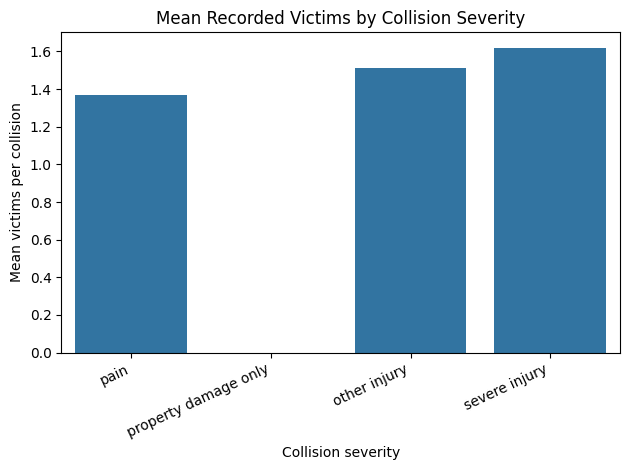

Interpret with caution: severity labels and victim count fields are source-recorded, not causal evidence.


In [22]:
# Collision-level victim count uses recorded injured + killed victims; missing values are not silently set to zero.
severity_victims = analysis_collisions.withColumn('recorded_victims', F.coalesce(F.col('injured_victims'),F.lit(0)) + F.coalesce(F.col('killed_victims'),F.lit(0)))
pdf = severity_victims.groupBy('collision_severity').agg(F.avg('recorded_victims').alias('mean_recorded_victims'),F.median('recorded_victims').alias('median_recorded_victims'),F.count('*').alias('collisions')).toPandas()
display(pdf)
sns.barplot(data=pdf, x='collision_severity', y='mean_recorded_victims'); plt.title('Mean Recorded Victims by Collision Severity'); plt.xlabel('Collision severity'); plt.ylabel('Mean victims per collision'); plt.xticks(rotation=25, ha='right'); plt.tight_layout(); plt.show()
print('Interpret with caution: severity labels and victim count fields are source-recorded, not causal evidence.')

##**3.1.6. Weather Conditions vs Collision Severity.** <font color = red>[5 marks]</font> <br>

Q: Analyze the correlation between weather conditions and collision severity.

collision_severity,other injury,pain,property damage only,severe injury
weather_clean,,,,
NaN,560,1194,2795,77
clear,97830,187235,466171,18669
cloudy,14153,28854,76571,2572
fog,517,754,2490,140
other,82,178,797,24
raining,3336,7962,20422,621
snowing,148,220,981,21
wind,54,89,233,14


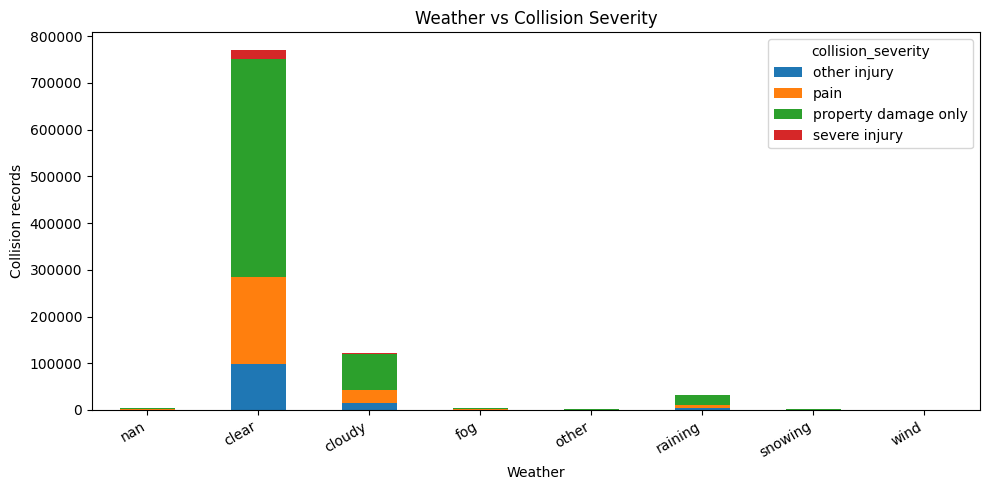

In [23]:
pdf = analysis_collisions.groupBy('weather_clean','collision_severity').count().toPandas()
pivot = pdf.pivot(index='weather_clean', columns='collision_severity', values='count').fillna(0)
display(pivot)
pivot.plot(kind='bar', stacked=True, figsize=(10,5)); plt.title('Weather vs Collision Severity'); plt.xlabel('Weather'); plt.ylabel('Collision records'); plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

##**3.1.7. Lighting conditions vs Collision Severity.** <font color = red>[5 marks]</font> <br>

Q:Visualize the impact of lighting conditions on collision severity.

collision_severity,other injury,pain,property damage only,severe injury
lighting_clean,,,,
NaN,580,1237,3410,74
dark with no street lights,10693,12088,48606,3245
dark with street lights,23715,42870,123456,5823
dark with street lights not functioning,226,386,1095,61
daylight,77317,162022,374175,12039
dusk or dawn,4149,7883,19718,896


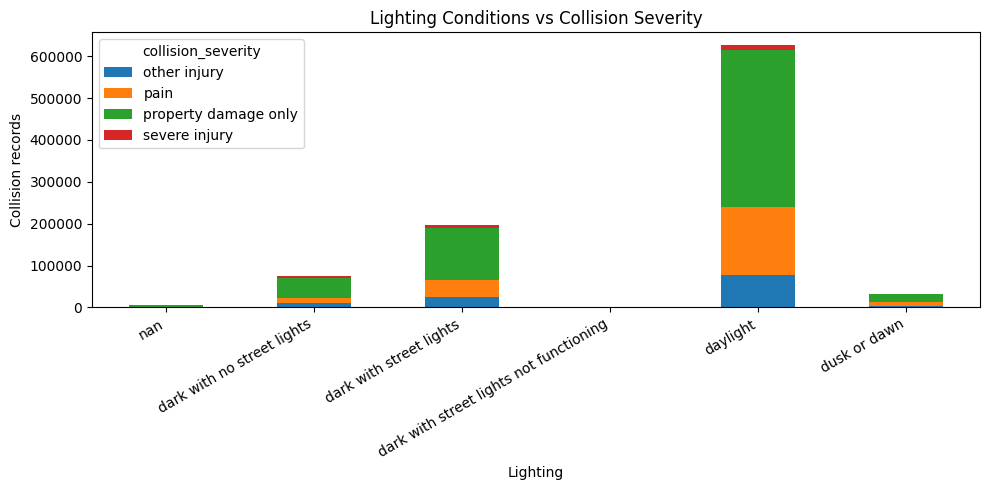

In [24]:
pdf = analysis_collisions.groupBy('lighting_clean','collision_severity').count().toPandas()
pivot = pdf.pivot(index='lighting_clean', columns='collision_severity', values='count').fillna(0)
display(pivot)
pivot.plot(kind='bar', stacked=True, figsize=(10,5)); plt.title('Lighting Conditions vs Collision Severity'); plt.xlabel('Lighting'); plt.ylabel('Collision records'); plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

##**3.1.8. Weekday-Wise Collision Trends.** <font color = red>[7 marks]</font> <br>

Q: Extract and analyze weekday-wise collision trends.

,weekday,count
1,Monday,131327
6,Tuesday,136968
3,Wednesday,137287
4,Thursday,138710
0,Friday,154539
5,Saturday,127855
2,Sunday,109078


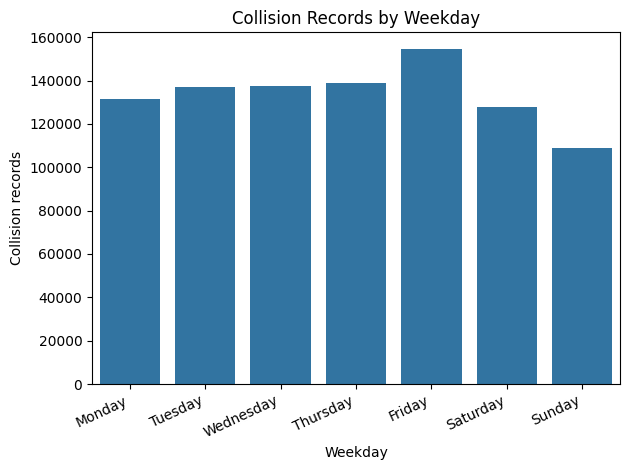

In [25]:
pdf = analysis_collisions.groupBy('weekday').count().toPandas()
pdf['weekday'] = pd.Categorical(pdf['weekday'], categories=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'], ordered=True)
pdf = pdf.sort_values('weekday'); display(pdf)
sns.barplot(data=pdf, x='weekday', y='count'); plt.title('Collision Records by Weekday'); plt.xlabel('Weekday'); plt.ylabel('Collision records'); plt.xticks(rotation=25, ha='right'); plt.tight_layout(); plt.show()

##**3.1.9. Spatial Distribution of Collisions.** <font color = red>[7 marks]</font> <br>

Q: Study spatial distribution of collisions by county.

,county_location_clean,count
0,los angeles,284088
1,orange,72038
2,san bernardino,56737
3,san diego,53103
4,riverside,48686
5,alameda,46521
6,sacramento,40503
7,santa clara,34115
8,contra costa,21460
9,san joaquin,20621


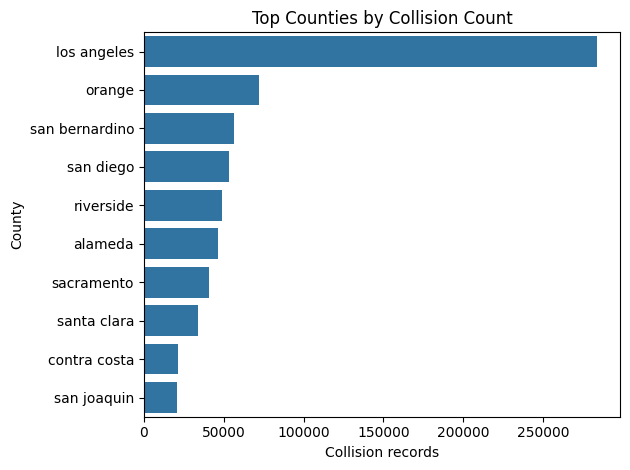

In [26]:
# County counts: raw frequency reflects both risk and exposure/population; it is not a per-capita rate.
pdf = analysis_collisions.groupBy('county_location_clean').count().orderBy(F.desc('count')).limit(20).toPandas()
display(pdf)
sns.barplot(data=pdf.head(10), y='county_location_clean', x='count'); plt.title('Top Counties by Collision Count'); plt.xlabel('Collision records'); plt.ylabel('County'); plt.tight_layout(); plt.show()

##**3.1.10. Collision Analysis by Geography.** <font color = red>[6 marks]</font> <br>

Q: Generate a scatter plot to analyze collision locations geographically.

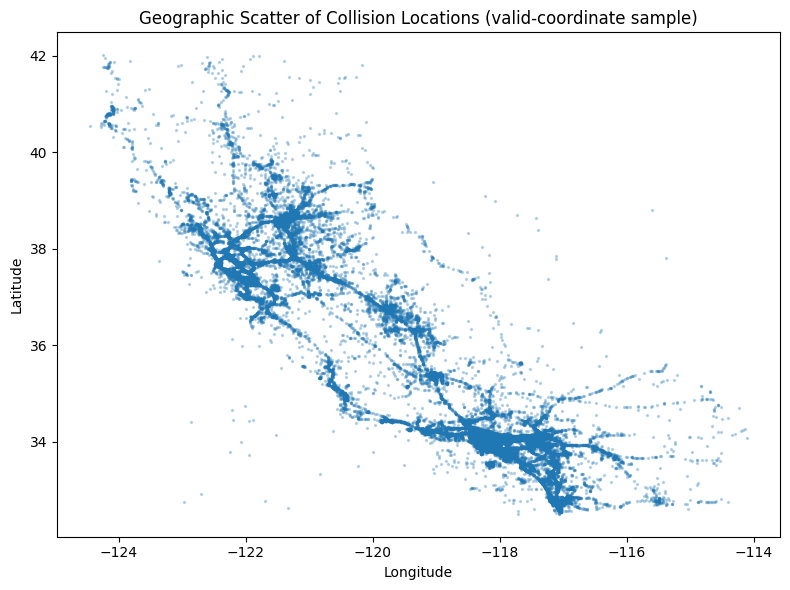

Points plotted: 40,247; sampling is for visualization only, not for the collision count queries.


In [27]:
geo = analysis_collisions.filter(F.col('coordinate_valid') == True).select(F.col('longitude').cast('double'),F.col('latitude').cast('double')).sample(False, 0.15, seed=42).limit(100000).toPandas()
plt.figure(figsize=(8,6)); plt.scatter(geo['longitude'], geo['latitude'], s=2, alpha=0.25)
plt.title('Geographic Scatter of Collision Locations (valid-coordinate sample)'); plt.xlabel('Longitude'); plt.ylabel('Latitude'); plt.tight_layout(); plt.show()
print(f'Points plotted: {len(geo):,}; sampling is for visualization only, not for the collision count queries.')

##**3.1.11. Collision Trends Over Time.** <font color = red>[10 marks]</font> <br>

Extract and analyzing collision trends over time.

In [28]:
# Extract year/month/hour from validated parsed date/time fields.
yearly = analysis_collisions.groupBy('collision_year').count().orderBy('collision_year').toPandas()
monthly = analysis_collisions.groupBy('collision_month').count().orderBy('collision_month').toPandas()
hourly = analysis_collisions.groupBy('collision_hour').count().orderBy('collision_hour').toPandas()
display(yearly); display(monthly); display(hourly)

,collision_year,count
0,2001,51894
1,2002,53708
2,2003,53605
3,2004,53704
4,2005,53074
5,2006,49642
6,2007,49560
7,2008,44882
8,2009,42421
9,2010,41320


,collision_month,count
0,1,78319
1,2,75779
2,3,82164
3,4,76207
4,5,78956
5,6,74760
6,7,74776
7,8,76957
8,9,77017
9,10,83272


,collision_hour,count
0,NaN,8084
1,0.0,18360
2,1.0,17567
3,2.0,17598
4,3.0,11943
5,4.0,10650
6,5.0,15280
7,6.0,25148
8,7.0,47494
9,8.0,48934


Q: Analyze yearly, monthly and hourly trends in collisions.

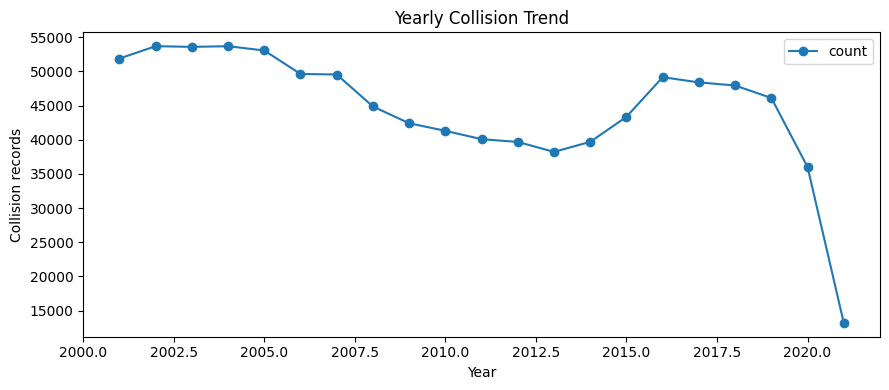

In [29]:
yearly.plot(x='collision_year', y='count', kind='line', marker='o', figsize=(9,4)); plt.title('Yearly Collision Trend'); plt.xlabel('Year'); plt.ylabel('Collision records'); plt.tight_layout(); plt.show()

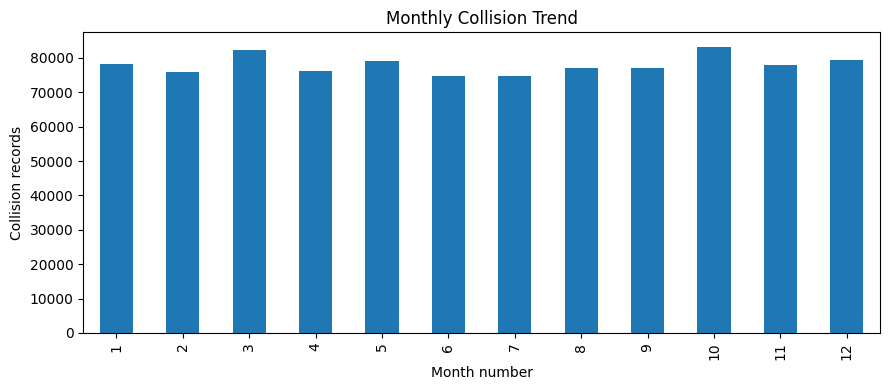

In [30]:
monthly.plot(x='collision_month', y='count', kind='bar', legend=False, figsize=(9,4)); plt.title('Monthly Collision Trend'); plt.xlabel('Month number'); plt.ylabel('Collision records'); plt.tight_layout(); plt.show()

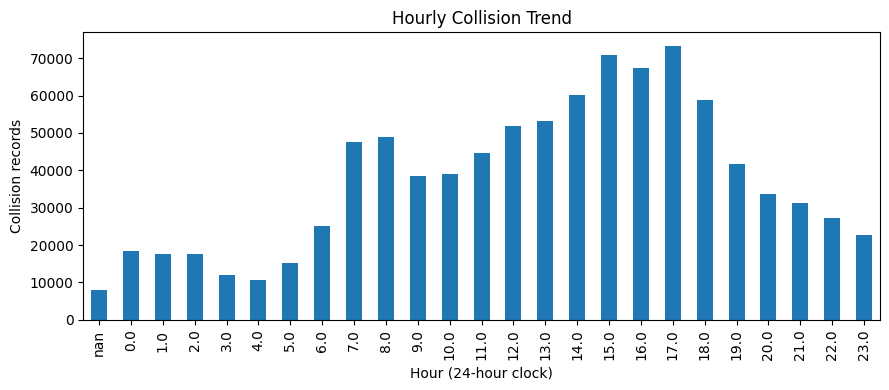

In [31]:
hourly.plot(x='collision_hour', y='count', kind='bar', legend=False, figsize=(9,4)); plt.title('Hourly Collision Trend'); plt.xlabel('Hour (24-hour clock)'); plt.ylabel('Collision records'); plt.tight_layout(); plt.show()

#**4. ETL Querying** <font color = red>[35 marks]</font> <br>

## **4.1. Top 5 Counties** <font color = red>[4 marks]</font> <br>

Q: Identify the top 5 counties with the highest number of collisions.

In [32]:
top_counties_df = analysis_collisions.groupBy('county_location_clean').count().orderBy(F.desc('count')).limit(5)
top_counties_df.show(truncate=False)

+---------------------+------+
|county_location_clean|count |
+---------------------+------+
|los angeles          |284088|
|orange               |72038 |
|san bernardino       |56737 |
|san diego            |53103 |
|riverside            |48686 |
+---------------------+------+



## **4.2. Month with Highest Collisions** <font color = red>[5 marks]</font> <br>

Q. Identify the month with the highest number of collisions.

In [33]:
month_query = analysis_collisions.groupBy('collision_month').count().orderBy(F.desc('count'))
month_query.show(1)

+---------------+-----+
|collision_month|count|
+---------------+-----+
|             10|83272|
+---------------+-----+
only showing top 1 row


## **4.3. Weather Conditions with Highest Collisions.** <font color = red>[5 marks]</font> <br>

Q. Determine the most common weather condition during collisions.

In [34]:
weather_query = analysis_collisions.groupBy('weather_clean').count().orderBy(F.desc('count'))
weather_query.show(10, truncate=False)

+-------------+------+
|weather_clean|count |
+-------------+------+
|clear        |769905|
|cloudy       |122150|
|raining      |32341 |
|NULL         |4626  |
|fog          |3901  |
|snowing      |1370  |
|other        |1081  |
|wind         |390   |
+-------------+------+



## **4.4. Fatal Collisions.** <font color = red>[5 marks]</font> <br>

Q. Calculate the percentage of collisions that resulted in fatalities.

In [35]:
# Source collision-level killed_victims field is used as the numerator and collision records as denominator.
# Validate this field before interpretation; if all values are zero/missing, explicitly flag the source limitation.
fatal_check = analysis_collisions.agg(F.count('*').alias('collision_records'),
    F.sum(F.when(F.col('killed_victims') > 0, 1).otherwise(0)).alias('collisions_with_killed_victims'),
    F.sum(F.coalesce(F.col('killed_victims'),F.lit(0))).alias('recorded_fatalities')).toPandas()
fatal_check['fatal_collision_pct'] = fatal_check['collisions_with_killed_victims'] / fatal_check['collision_records'] * 100
display(fatal_check)
if float(fatal_check['recorded_fatalities'].iloc[0] or 0) == 0:
    print('DATA QUALITY LIMITATION: killed_victims is zero for all non-null records in this supplied collision extract. The fatal-collision percentage from this field is not reliable; verify against the victims table after validating cross-table case_id formats.')

,collision_records,collisions_with_killed_victims,recorded_fatalities,fatal_collision_pct
0,935764,0,0.0,0.0


DATA QUALITY LIMITATION: killed_victims is zero for all non-null records in this supplied collision extract. The fatal-collision percentage from this field is not reliable; verify against the victims table after validating cross-table case_id formats.


## **4.5. Dangerous Time for Collisions.** <font color = red>[5 marks]</font> <br>

Q. Find the most dangerous time of day for collisions.

In [36]:
# Most dangerous time of day by raw frequency; this measures counts, not exposure-adjusted risk.
analysis_collisions.groupBy('collision_hour').count().orderBy(F.desc('count')).show(5)

+--------------+-----+
|collision_hour|count|
+--------------+-----+
|            17|73252|
|            15|70855|
|            16|67431|
|            14|60156|
|            18|58850|
+--------------+-----+
only showing top 5 rows


## **4.6. Road Surface Conditions.** <font color = red>[5 marks]</font> <br>

Q. Identify the top 5 road surface conditions with the highest collision frequency.

In [37]:
# Road-surface labels (assignment question refers to road surface conditions).
analysis_collisions.groupBy('road_surface_clean').count().orderBy(F.desc('count')).show(10, truncate=False)

+------------------+------+
|road_surface_clean|count |
+------------------+------+
|dry               |845612|
|wet               |76831 |
|NULL              |8141  |
|snowy             |4122  |
|slippery          |1048  |
|h                 |10    |
+------------------+------+



## **4.7. Lighting Conditions.** <font color = red>[5 marks]</font> <br>

Q. Analyze lighting conditions that contribute to the highest number of collisions.

In [38]:
analysis_collisions.groupBy('lighting_clean').count().orderBy(F.desc('count')).show(10, truncate=False)

+---------------------------------------+------+
|lighting_clean                         |count |
+---------------------------------------+------+
|daylight                               |625553|
|dark with street lights                |195864|
|dark with no street lights             |74632 |
|dusk or dawn                           |32646 |
|NULL                                   |5301  |
|dark with street lights not functioning|1768  |
+---------------------------------------+------+



#5. Conclusion <font color = red>[10 marks]</font> <br>

Write your conclusion.

In [39]:
# Final conclusions should be read alongside the computed tables/plots above.
print('1. Raw collision counts are highest in the leading counties and weekday/hour peaks shown by the query outputs.')
print('2. Clear weather and dry road surfaces dominate the records; these are also common exposure conditions, so counts alone do not establish increased risk.')
print('3. Compare severity shares across weather and lighting groups rather than inferring causation from raw totals.')
print('4. Use county and coordinate patterns to prioritize validation and field review, then normalize by traffic volume/population where possible.')
print('5. Fatality metric requires caution because the supplied collision extract records killed_victims as zero across all non-null rows; validate victim-to-collision joins before reporting a fatality percentage.')
print('6. Recommend targeted lighting/visibility audits, speed management during afternoon/evening peaks, and pedestrian/cyclist infrastructure review in high-count locations.')


1. Raw collision counts are highest in the leading counties and weekday/hour peaks shown by the query outputs.
2. Clear weather and dry road surfaces dominate the records; these are also common exposure conditions, so counts alone do not establish increased risk.
3. Compare severity shares across weather and lighting groups rather than inferring causation from raw totals.
4. Use county and coordinate patterns to prioritize validation and field review, then normalize by traffic volume/population where possible.
5. Fatality metric requires caution because the supplied collision extract records killed_victims as zero across all non-null rows; validate victim-to-collision joins before reporting a fatality percentage.
6. Recommend targeted lighting/visibility audits, speed management during afternoon/evening peaks, and pedestrian/cyclist infrastructure review in high-count locations.
